# ArRAG-Eval — Ablation Analysis

Visual comparison of the **dense**, **hybrid (RRF)**, and **agentic** retrieval
configurations, pulled directly from the `ArRAG-Eval` MLFlow experiment.

Run `experiments/run_ablation.py` first if you haven't — this notebook reads
its results, it doesn't regenerate them.

**A note on what these numbers are and aren't:** every metric here comes from
an LLM judge (qwen3:4b) grading another LLM's output, on 20 questions. That's
enough to see whether hybrid retrieval clearly beats dense, or whether the
agentic loop is worth its extra latency — but treat the *absolute* scores as
noisy, and the *relative* ordering between configs as the signal. If you want
tighter confidence before publishing, `NUM_TEST_SAMPLES` in
`run_ablation.py` is the lever to raise.

## 0. Setup

In [1]:
# in the notebook
import mlflow
print("Notebook mlflow version:", mlflow.__version__)

f:\arrag-eval\.myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Notebook mlflow version: 3.12.0


In [2]:
import json
import mlflow
import mlflow.artifacts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 100)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11
mlflow.set_tracking_uri("sqlite:///F:/arrag-eval/mlflow.db")

MLFLOW_EXPERIMENT_NAME = "ArRAG-Eval-Full"
METRICS = ["context_precision", "faithfulness", "answer_relevance"]
METRIC_LABELS = {
    "context_precision": "Context Precision",
    "faithfulness": "Faithfulness",
    "answer_relevance": "Answer Relevance",
}
# Read naturally as a progression: what hybrid buys you over dense,
# what agentic buys you over hybrid.
PREFERRED_ORDER = ["ablation-dense", "ablation-hybrid", "ablation-agentic"]

In [3]:
import mlflow

print("Notebook's current tracking URI:", mlflow.get_tracking_uri())
print()
print("Experiments visible at that URI:")
for exp in mlflow.search_experiments():
    print(f"  - {exp.name}  (id={exp.experiment_id})")

Notebook's current tracking URI: sqlite:///F:/arrag-eval/mlflow.db

Experiments visible at that URI:
  - ArRAG-Eval-Full  (id=3)
  - ArRAG-Eval_semantic_metrics  (id=2)
  - ArRAG-Eval  (id=1)
  - Default  (id=0)


## 1. Load runs from MLFlow

In [4]:
runs_df = mlflow.search_runs(experiment_names=[MLFLOW_EXPERIMENT_NAME])

if runs_df.empty:
    raise RuntimeError(
        f"No runs found in experiment '{MLFLOW_EXPERIMENT_NAME}'. "
        f"Run experiments/run_ablation.py (and/or run_baseline_with_mlflow.py) first."
    )

print(f"Found {len(runs_df)} runs")

preview_cols = ["run_id", "start_time", "params.experiment_name"] + [f"metrics.{m}" for m in METRICS]
preview_cols = [c for c in preview_cols if c in runs_df.columns]
runs_df[preview_cols].sort_values("start_time", ascending=False)

Found 4 runs


,run_id,start_time,params.experiment_name,metrics.context_precision,metrics.faithfulness,metrics.answer_relevance
0,bbf7a6892583483e81a47fe418bc10d6,2026-07-21 15:20:12.377000+00:00,ablation-agentic,0.315902,0.594444,0.796792
1,6becd9df77a042a49a23473357a83759,2026-07-21 13:00:07.762000+00:00,ablation-hybrid,0.361683,0.516190,0.799373
2,69ca8a987bf04ffaadac81bf5db0ef93,2026-07-21 10:38:32.142000+00:00,ablation-dense,0.374395,0.580417,0.811741
3,2e944a00eaeb4535a66a0a8b925b507c,2026-07-20 16:36:12.640000+00:00,ablation-dense,NaN,NaN,NaN


## 2. Keep only the latest run per configuration

If you reran an ablation config after a fix, the experiment will have more
than one run with the same `experiment_name`. Same dedup rule as
`scripts/create_ablation_table.py`: keep the most recent one per config so a
stale, possibly-broken earlier run doesn't sneak into the comparison.

In [5]:
if "params.experiment_name" not in runs_df.columns:
    raise RuntimeError(
        "No runs have an 'experiment_name' param logged — check you're using "
        "the current run_ablation.py / run_baseline_with_mlflow.py."
    )

latest_runs = (
    runs_df.sort_values("start_time")
    .groupby("params.experiment_name", as_index=False)
    .tail(1)
    .set_index("params.experiment_name")
)


def ordered_index(idx):
    known = [n for n in PREFERRED_ORDER if n in idx]
    rest = sorted(n for n in idx if n not in PREFERRED_ORDER)
    return known + rest


latest_runs = latest_runs.loc[ordered_index(latest_runs.index)]
latest_runs[[f"metrics.{m}" for m in METRICS]]

,metrics.context_precision,metrics.faithfulness,metrics.answer_relevance
params.experiment_name,,,
ablation-dense,0.374395,0.580417,0.811741
ablation-hybrid,0.361683,0.516190,0.799373
ablation-agentic,0.315902,0.594444,0.796792


## 3. Grouped bar chart — the headline comparison

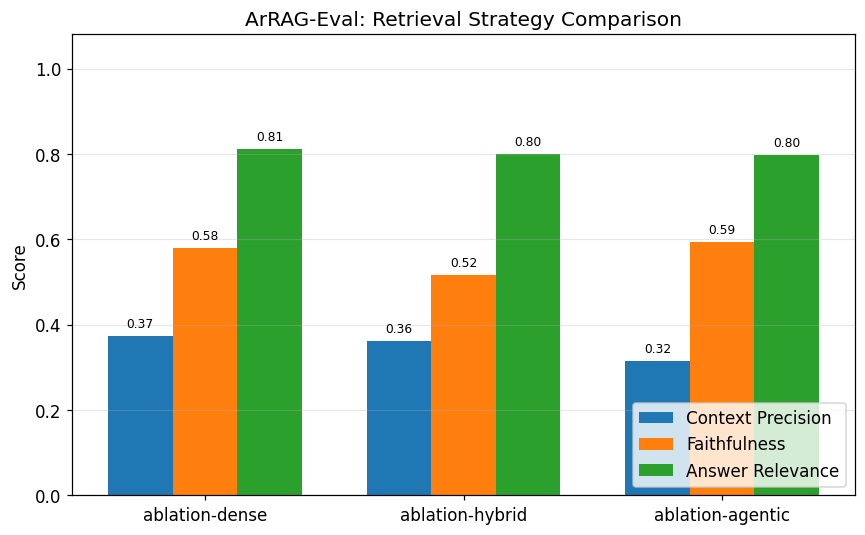

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(latest_runs.index))
width = 0.25

for i, metric in enumerate(METRICS):
    values = latest_runs[f"metrics.{metric}"].values
    bars = ax.bar(x + i * width, values, width, label=METRIC_LABELS[metric])
    for xi, v in zip(x + i * width, values):
        ax.text(xi, v + 0.02, f"{v:.2f}", ha="center", fontsize=8)

ax.set_xticks(x + width)
ax.set_xticklabels(latest_runs.index, rotation=0)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Score")
ax.set_title("ArRAG-Eval: Retrieval Strategy Comparison")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("ablation_comparison.png", dpi=150)
plt.show()

## 4. Percent change between configs

Same framing as the roadmap's "what to share on LinkedIn" example
(`+12% improvement`) — dense → hybrid isolates what RRF fusion buys you;
hybrid → agentic isolates what decomposition + the sufficiency loop buy you
on top of that.

In [7]:
def print_delta(name_a, name_b, df):
    if name_a not in df.index or name_b not in df.index:
        print(f"Skipping {name_a} -> {name_b}: one or both configs not found in this experiment yet.")
        return
    a, b = df.loc[name_a], df.loc[name_b]
    for metric in METRICS:
        va, vb = a[f"metrics.{metric}"], b[f"metrics.{metric}"]
        pct = f"({(vb - va) / va * 100:+.1f}%)" if va > 0 else "(n/a, baseline is 0)"
        print(f"  {METRIC_LABELS[metric]:20s}  {name_a}={va:.3f}  {name_b}={vb:.3f}  {pct}")


print(f"{PREFERRED_ORDER[0]} -> {PREFERRED_ORDER[1]}:")
print_delta(PREFERRED_ORDER[0], PREFERRED_ORDER[1], latest_runs)

print(f"\n{PREFERRED_ORDER[1]} -> {PREFERRED_ORDER[2]}:")
print_delta(PREFERRED_ORDER[1], PREFERRED_ORDER[2], latest_runs)

ablation-dense -> ablation-hybrid:
  Context Precision     ablation-dense=0.374  ablation-hybrid=0.362  (-3.4%)
  Faithfulness          ablation-dense=0.580  ablation-hybrid=0.516  (-11.1%)
  Answer Relevance      ablation-dense=0.812  ablation-hybrid=0.799  (-1.5%)

ablation-hybrid -> ablation-agentic:
  Context Precision     ablation-hybrid=0.362  ablation-agentic=0.316  (-12.7%)
  Faithfulness          ablation-hybrid=0.516  ablation-agentic=0.594  (+15.2%)
  Answer Relevance      ablation-hybrid=0.799  ablation-agentic=0.797  (-0.3%)


## 5. Per-question score distributions

The bar chart above shows means, which hide variance — a config that's
consistently mediocre and a config that's brilliant half the time and broken
half the time can post the same average. This pulls the per-sample
`scores.json` artifact each `run_ablation.py` run logs and box-plots the
actual spread.

(Note: `run_baseline_with_metrics.py` logs the equivalent file as
`detailed_scores.json` instead of `scores.json` — same structure, different
name, since that script predates the ablation script. Only the
`ablation-*` runs are expected to have `scores.json`.)

In [8]:
def load_detailed_scores(run_id):
    '''Download and parse the per-sample scores.json artifact logged by run_ablation.py.'''
    local_path = mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path="scores.json")
    with open(local_path, "r", encoding="utf-8") as f:
        return json.load(f)


per_sample = {}
for config_name in latest_runs.index:
    run_id = latest_runs.loc[config_name, "run_id"]
    try:
        per_sample[config_name] = load_detailed_scores(run_id)
    except Exception as e:
        print(f"Could not load scores.json for {config_name}: {e}")

print(f"Loaded per-sample scores for: {list(per_sample.keys())}")

Loaded per-sample scores for: ['ablation-dense', 'ablation-hybrid', 'ablation-agentic']


C:\Users\youss\AppData\Local\Temp\ipykernel_26912\3131717237.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels)
C:\Users\youss\AppData\Local\Temp\ipykernel_26912\3131717237.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels)
C:\Users\youss\AppData\Local\Temp\ipykernel_26912\3131717237.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels)


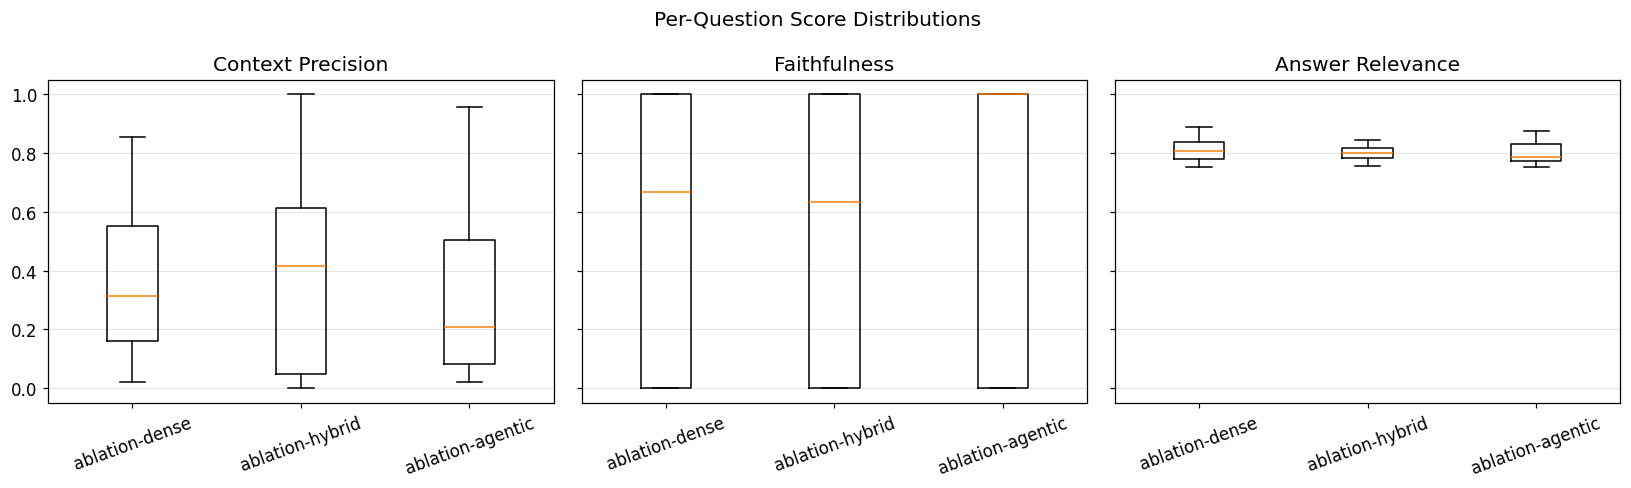

In [9]:
if per_sample:
    fig, axes = plt.subplots(1, len(METRICS), figsize=(5 * len(METRICS), 4.5), sharey=True)
    if len(METRICS) == 1:
        axes = [axes]

    for ax, metric in zip(axes, METRICS):
        data, labels = [], []
        for config_name in latest_runs.index:
            if config_name not in per_sample:
                continue
            scores = [
                sample[metric]["score"]
                for sample in per_sample[config_name]
                if metric in sample
            ]
            if scores:
                data.append(scores)
                labels.append(config_name)
        if data:
            ax.boxplot(data, labels=labels)
        ax.set_title(METRIC_LABELS[metric])
        ax.set_ylim(-0.05, 1.05)
        ax.tick_params(axis="x", rotation=20)
        ax.grid(axis="y", alpha=0.3)

    plt.suptitle("Per-Question Score Distributions")
    plt.tight_layout()
    plt.savefig("ablation_distributions.png", dpi=150)
    plt.show()
else:
    print("No per-sample scores.json artifacts found for any config — skipping distribution plots.")

## 6. Radar chart

Same numbers, different framing — useful as a single publishable image.

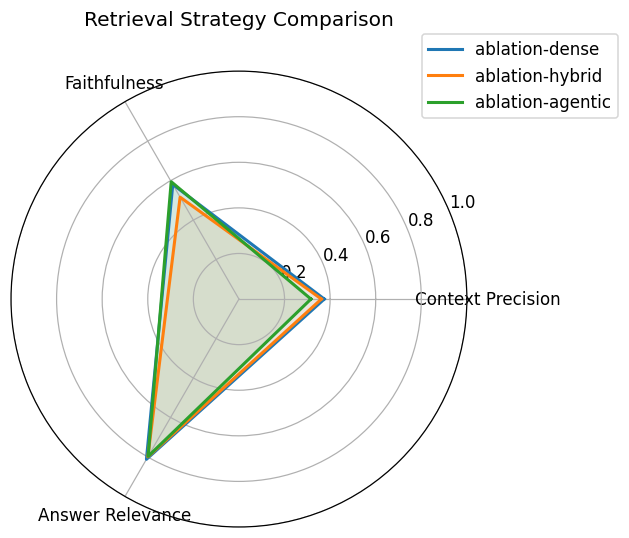

In [10]:
categories = [METRIC_LABELS[m] for m in METRICS]
num_vars = len(categories)
angles = [n / float(num_vars) * 2 * pi for n in range(num_vars)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

for config_name in latest_runs.index:
    values = [latest_runs.loc[config_name, f"metrics.{m}"] for m in METRICS]
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=config_name)
    ax.fill(angles, values, alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)
ax.set_ylim(0, 1)
ax.set_title("Retrieval Strategy Comparison", y=1.08)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))

plt.tight_layout()
plt.savefig("ablation_radar.png", dpi=150)
plt.show()

## 7. Markdown summary table

Same output as `scripts/create_ablation_table.py`, reproduced here so the notebook is self-contained.

In [11]:
summary_lines = ["| Configuration | " + " | ".join(METRIC_LABELS[m] for m in METRICS) + " |"]
summary_lines.append("|---" * (len(METRICS) + 1) + "|")
for config_name in latest_runs.index:
    cells_ = [config_name] + [f"{latest_runs.loc[config_name, f'metrics.{m}']:.3f}" for m in METRICS]
    summary_lines.append("| " + " | ".join(cells_) + " |")

summary_md = "\n".join(summary_lines)
display(Markdown(summary_md))

| Configuration | Context Precision | Faithfulness | Answer Relevance |
|---|---|---|---|
| ablation-dense | 0.374 | 0.580 | 0.812 |
| ablation-hybrid | 0.362 | 0.516 | 0.799 |
| ablation-agentic | 0.316 | 0.594 | 0.797 |

## Notes / caveats before publishing

- **Sample size**: 20 questions is enough to spot a config that's clearly
  broken, not enough to claim a precise percentage improvement with
  confidence — small differences between configs may just be noise.
- **The judge is not ground truth**: faithfulness/relevance/precision are
  all graded by the same qwen3:4b model that's also generating (some of)
  the answers being graded. Systematic judge biases apply equally across
  configs, so the *relative* comparison is more trustworthy than any
  single config's *absolute* score.
- **Agentic isn't free**: if `ablation-agentic` doesn't clearly beat
  `ablation-hybrid`, that's a real finding worth reporting as-is — the
  extra decomposition + sufficiency-check latency isn't automatically
  worth it, and "we tried X and it didn't help" is a legitimate ablation
  result.